# Huấn luyện 4 mô hình ALL từ pipeline Geometry đã chốt

Notebook này dùng **kết quả của `ALL_Pipeline_Geometry_4Models.ipynb`** (thư mục `auto_group_phash4_v1` trên Drive):
`main_pipeline_config.json`, `manifest_with_splits.csv`, `split_pairs.csv`, `class_weights.json`.
Split train/val/test 70/15/15 theo nhóm SHA + pHash (không rò rỉ), augmentation Geometry chỉ cho train, chuẩn hóa ImageNet, ảnh RGB 224×224.

| Mã | Mô hình | Khởi tạo |
|---|---|---|
| E1 | CNN tự xây (`custom_cnn`) | từ đầu |
| E2 | ResNet50 (`resnet50`) | ImageNet1K_V2 |
| E3 | EfficientNet-B0 (`efficientnet_b0`) | ImageNet1K_V1 |
| E4 | MobileNetV2 (`mobilenet_v2`) | ImageNet1K_V2 |

Mỗi mô hình chạy riêng cho hai view **Original** và **Segmented**. Chọn checkpoint theo **val loss thấp nhất** (cùng tiêu chí đã dùng để chốt Geometry); tập test chỉ được duyệt **một lần** sau khi huấn luyện xong.

**Chuẩn bị:** đã chạy hết notebook pipeline ít nhất một lần; `MyDrive/ALL_project/data-ALL.zip` còn nguyên. Runtime → Change runtime type → **T4 GPU**.
Nếu Colab bị ngắt: chạy lại ô 1–5 rồi chạy lại ô 6; các lần chạy đã xong (có `metrics.json`) được bỏ qua.

In [ ]:
# 1. Kiểm tra GPU
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "Không có GPU — vẫn chạy được nhưng rất chậm"

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
# 2. Cấu hình, kết nối Drive, giải nén dữ liệu vào ổ cục bộ Colab
from pathlib import Path
import json, random, hashlib, time, zipfile, platform
import numpy as np, pandas as pd
import torch, torchvision

from google.colab import drive
drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/ALL_project')
PIPELINE_DIR = PROJECT / 'ALL_preprocessing_separate' / 'auto_group_phash4_v1'   # đầu ra notebook pipeline
ZIP_PATH = PROJECT / 'data-ALL.zip'
EXTRACT_DIR = Path('/content/ALL_data')
DATA_ROOT = EXTRACT_DIR / 'data-ALL'
RESULTS = PROJECT / 'training_results' / 'geometry_v1'
RESULTS.mkdir(parents=True, exist_ok=True)

# Split đã dùng khi chốt Geometry — không khớp thì dừng, không ép chạy.
REFERENCE_SPLIT_FINGERPRINT = '771c797e0be7ad26144f24249802bccefbf3bd4a7363d8d86084e9f77163edcf'

MODELS_TO_RUN = ['custom_cnn', 'resnet50', 'efficientnet_b0', 'mobilenet_v2']
VIEWS_TO_RUN = ['original', 'segmented']
SEEDS = [42]            # thêm 43, 44 để báo cáo trung bình ± độ lệch chuẩn
MAX_EPOCHS = 30
PATIENCE = 6            # dừng sớm theo val loss
NUM_WORKERS = 2
BATCH_SIZE = 32
HPARAMS = {             # lr cho backbone / classifier
    'custom_cnn':      dict(lr_backbone=1e-3, lr_head=1e-3, weight_decay=1e-4),
    'resnet50':        dict(lr_backbone=1e-4, lr_head=1e-3, weight_decay=1e-4),
    'efficientnet_b0': dict(lr_backbone=2e-4, lr_head=1e-3, weight_decay=1e-4),
    'mobilenet_v2':    dict(lr_backbone=2e-4, lr_head=1e-3, weight_decay=1e-4),
}

for f in ['main_pipeline_config.json', 'manifest_with_splits.csv', 'split_pairs.csv', 'class_weights.json']:
    if not (PIPELINE_DIR / f).is_file():
        raise FileNotFoundError(f'Thiếu {PIPELINE_DIR/f} — hãy chạy notebook pipeline trước.')

if not all((DATA_ROOT / v).is_dir() for v in ['Original', 'Segmented']):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| device', device)
print('Pipeline:', PIPELINE_DIR); print('Dữ liệu:', DATA_ROOT); print('Kết quả:', RESULTS)

Mounted at /content/drive
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device cuda
Pipeline: /content/drive/MyDrive/ALL_project/ALL_preprocessing_separate/auto_group_phash4_v1
Dữ liệu: /content/ALL_data/data-ALL
Kết quả: /content/drive/MyDrive/ALL_project/training_results/geometry_v1


## Pipeline dữ liệu (đọc từ kết quả notebook pipeline)
Ô dưới định nghĩa lại đúng `CellTransform` / `ALLImageDataset` / `build_main_pipeline` bản **Geometry** của notebook pipeline (cell `final-016`), đọc cấu hình và CSV trong `PIPELINE_DIR`.
Làm vậy vì file `all_data_pipeline.py` hiện trên Drive là một bản khác (có color jitter và cần khóa `background_pixel_threshold` không có trong `main_pipeline_config.json`), import nó sẽ lỗi `KeyError`.
Mọi kiểm tra fingerprint, khớp manifest–split và chống rò rỉ nhóm được giữ nguyên.

In [ ]:
# 3. Pipeline Geometry (giống cell final-016 của notebook pipeline)
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.transforms import functional as TF, InterpolationMode

class CellTransform:
    def __init__(self, stats, config, training, input_size):
        self.mean, self.std = stats['mean'], stats['std']
        self.cfg, self.training, self.size = config, training, input_size
    def __call__(self, image, view):
        image = image.convert('RGB')
        if image.size != (self.size, self.size):
            raise ValueError(f'Cần ảnh {self.size}×{self.size}, nhận {image.size}')
        if self.training:
            cfg = self.cfg
            if cfg['rotation'] or cfg['translate'] or tuple(cfg['scale']) != (1.0, 1.0):
                arr = np.asarray(image)
                border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
                fill = (0, 0, 0) if view == 'segmented' else tuple(int(v) for v in np.median(border, axis=0))
                angle, translation, scale, shear = T.RandomAffine.get_params(
                    [-cfg['rotation'], cfg['rotation']], [cfg['translate']] * 2,
                    list(cfg['scale']), None, list(image.size))
                image = TF.affine(image, angle, translation, scale, shear,
                                  interpolation=InterpolationMode.BILINEAR, fill=fill)
            if torch.rand(()).item() < cfg['flip_p']:
                image = TF.hflip(image)
            if torch.rand(()).item() < cfg['flip_p']:
                image = TF.vflip(image)
        return TF.normalize(TF.to_tensor(image), self.mean, self.std)

class ALLImageDataset(Dataset):
    def __init__(self, rows, transform, root):
        self.rows = rows.reset_index(drop=True).copy()
        self.transform, self.root = transform, Path(root)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        row = self.rows.iloc[i]
        with Image.open(self.root / row.relative_path) as im:
            x = self.transform(im, row['view'])
        return x, int(row.target)

def seed_worker(worker_id):
    s = torch.initial_seed() % (2**32)
    random.seed(s); np.random.seed(s)

def build_main_pipeline(model_name, pipeline_dir, data_root, batch_size=None, num_workers=None, seed=None):
    folder = Path(pipeline_dir)
    cfg = json.loads((folder / 'main_pipeline_config.json').read_text(encoding='utf-8'))
    if model_name not in cfg['normalization']:
        raise ValueError(f'Mô hình không hợp lệ: {model_name}')
    if cfg['input_size'] != [3, 224, 224] or cfg['resize'] or cfg['center_crop']:
        raise ValueError('Thiết lập kích thước không được hỗ trợ')
    for view in ('original', 'segmented'):
        if set(cfg['augmentation'][view]) != {'rotation', 'translate', 'scale', 'flip_p'}:
            raise ValueError('Cấu hình không phải Geometry — chạy lại notebook pipeline.')
    rows = pd.read_csv(folder / cfg['manifest_file'], keep_default_na=False)
    split = pd.read_csv(folder / cfg['split_file'], keep_default_na=False)
    cols = ['sample_id', 'label', 'original', 'segmented', 'group_id', 'content_fingerprint', 'split']
    fp = hashlib.sha256(split[cols].sort_values('sample_id').to_csv(index=False).encode('utf-8')).hexdigest()
    if fp != cfg['split_fingerprint'] or fp != REFERENCE_SPLIT_FINGERPRINT:
        raise RuntimeError('Split khác thời điểm chốt pipeline')
    expected = split[['sample_id', 'group_id', 'split', 'label', 'target']].sort_values('sample_id').reset_index(drop=True)
    for view in ['original', 'segmented']:
        actual = rows[rows['view'] == view][expected.columns].sort_values('sample_id').reset_index(drop=True)
        if not actual.equals(expected):
            raise RuntimeError(f'Manifest/split không khớp: {view}')
        if rows[rows['view'] == view].set_index('sample_id')['relative_path'].sort_index().to_dict() != \
           split.set_index('sample_id')[view].sort_index().to_dict():
            raise RuntimeError(f'Đường dẫn manifest/split không khớp: {view}')
    if rows.duplicated(['sample_id', 'view']).any() or (rows.groupby('group_id')['split'].nunique() > 1).any():
        raise RuntimeError('Manifest bị trùng khóa hoặc group nằm khác tập')
    bs = cfg['batch_size'] if batch_size is None else batch_size
    nw = cfg['num_workers'] if num_workers is None else num_workers
    g_seed = cfg['seed'] if seed is None else seed
    loaders, weights = {}, {}
    for view in ['original', 'segmented']:
        tr = rows[(rows['view'] == view) & (rows['split'] == 'train')]
        counts = tr.target.value_counts().reindex(range(len(cfg['classes'])), fill_value=0)
        if (counts == 0).any():
            raise RuntimeError('Train thiếu lớp')
        weights[view] = torch.tensor(len(tr) / (len(cfg['classes']) * counts.to_numpy()), dtype=torch.float32)
        for s in ['train', 'val', 'test']:
            sel = rows[(rows['view'] == view) & (rows['split'] == s)]
            tf = CellTransform(cfg['normalization'][model_name], cfg['augmentation'][view], s == 'train', cfg['input_size'][1])
            loaders[f'{s}_{view}'] = DataLoader(
                ALLImageDataset(sel, tf, data_root), batch_size=bs, shuffle=(s == 'train'),
                num_workers=nw, pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker,
                generator=torch.Generator().manual_seed(g_seed), persistent_workers=nw > 0)
    return loaders, weights, cfg

# Kiểm tra nhanh + đối chiếu trọng số lớp với class_weights.json đã lưu
_loaders, _weights, PIPE_CFG = build_main_pipeline('custom_cnn', PIPELINE_DIR, DATA_ROOT, BATCH_SIZE, 0)
CLASSES = sorted(PIPE_CFG['classes'], key=PIPE_CFG['classes'].get)
saved_w = json.loads((PIPELINE_DIR / 'class_weights.json').read_text())
for v in VIEWS_TO_RUN:
    assert np.allclose(_weights[v].numpy(), [saved_w[v][c] for c in CLASSES], atol=1e-5), 'Trọng số lớp lệch file đã lưu'
x, y = next(iter(_loaders['val_original']))
assert x.shape[1:] == (3, 224, 224) and y.dtype == torch.int64
print('Lớp:', CLASSES)
print({k: len(l.dataset) for k, l in _loaders.items()})
print('Trọng số lớp:', {v: [round(w, 3) for w in _weights[v].tolist()] for v in VIEWS_TO_RUN})
del _loaders

Lớp: ['Benign', 'Early', 'Pre', 'Pro']
{'train_original': 2281, 'val_original': 484, 'test_original': 491, 'train_segmented': 2281, 'val_segmented': 484, 'test_segmented': 491}
Trọng số lớp: {'original': [1.615, 0.823, 0.85, 1.011], 'segmented': [1.615, 0.823, 0.85, 1.011]}


In [ ]:
# 4. Mô hình
import torch.nn as nn
from torchvision import models as tvm

class CustomCNN(nn.Module):
    """CNN tự xây: 5 khối Conv-BN-ReLU-Conv-BN-ReLU-MaxPool, GAP, dropout, 4 logits."""
    def __init__(self, n_classes=4, widths=(32, 64, 128, 256, 384), dropout=0.4):
        super().__init__()
        layers, c_in = [], 3
        for w in widths:
            layers += [nn.Conv2d(c_in, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = w
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_model(name, n_classes=4):
    """Trả (model, head_params) — head_params là tham số classifier mới (lr cao hơn)."""
    if name == 'custom_cnn':
        m = CustomCNN(n_classes); head = m.classifier
    elif name == 'resnet50':
        m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, n_classes); head = m.fc
    elif name == 'efficientnet_b0':
        m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n_classes); head = m.classifier
    elif name == 'mobilenet_v2':
        m = tvm.mobilenet_v2(weights=tvm.MobileNet_V2_Weights.IMAGENET1K_V2)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n_classes); head = m.classifier
    else:
        raise ValueError(name)
    return m, list(head.parameters())

for n in MODELS_TO_RUN:
    m, _ = build_model(n)
    with torch.no_grad():
        assert m.eval()(torch.zeros(2, 3, 224, 224)).shape == (2, 4)
    print(f'{n:16s} {sum(p.numel() for p in m.parameters())/1e6:6.2f} M tham số')
    del m

custom_cnn         3.39 M tham số
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 160MB/s]


resnet50          23.52 M tham số
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 129MB/s]


efficientnet_b0    4.01 M tham số
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]

mobilenet_v2       2.23 M tham số


In [ ]:
# 5. Huấn luyện, đánh giá
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

def reset_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs, ys = [], []
    for x, y in loader:
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            logits = model(x.to(device, non_blocking=True))
        probs.append(torch.softmax(logits.float(), 1).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def compute_metrics(y, prob):
    pred = prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, labels=range(4), average='macro', zero_division=0)
    per_r = precision_recall_fscore_support(y, pred, labels=range(4), average=None, zero_division=0)[1]
    mal_true, mal_pred = y != 0, pred != 0           # ác tính = Early/Pre/Pro; lành = Benign
    return dict(
        accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
        macro_precision=p, macro_recall=r, macro_f1=f1,
        auc_ovr=roc_auc_score(y, prob, multi_class='ovr', labels=range(4)),
        malignant_sensitivity=(mal_pred & mal_true).sum() / max(mal_true.sum(), 1),
        specificity_benign=(~mal_pred & ~mal_true).sum() / max((~mal_true).sum(), 1),
        missed_malignant=int((mal_true & ~mal_pred).sum()),
        **{f'recall_{c}': per_r[i] for i, c in enumerate(CLASSES)})

def run_experiment(model_name, view, seed):
    run_dir = RESULTS / 'runs' / f'{model_name}_{view}_s{seed}'
    if (run_dir / 'metrics.json').exists():
        print(f'[{run_dir.name}] đã xong — bỏ qua'); return json.loads((run_dir / 'metrics.json').read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    reset_seed(seed)
    loaders, class_w, _ = build_main_pipeline(model_name, PIPELINE_DIR, DATA_ROOT, BATCH_SIZE, NUM_WORKERS, seed)
    train_l, val_l, test_l = loaders[f'train_{view}'], loaders[f'val_{view}'], loaders[f'test_{view}']
    model, head = build_model(model_name); model.to(device)
    hp = HPARAMS[model_name]
    head_ids = {id(p) for p in head}
    groups = [{'params': [p for p in model.parameters() if id(p) not in head_ids], 'lr': hp['lr_backbone']},
              {'params': head, 'lr': hp['lr_head']}]
    opt = torch.optim.AdamW([g for g in groups if g['params']], weight_decay=hp['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)
    criterion = nn.CrossEntropyLoss(weight=class_w[view].to(device))
    scaler = torch.amp.GradScaler(enabled=device.type == 'cuda')
    best, wait, hist = float('inf'), 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time(); model.train(); tot, correct, n = 0.0, 0, 0
        for x, y in train_l:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
        sched.step()
        vp, vy = predict(model, val_l)
        val_loss = criterion(torch.log(torch.tensor(vp).clamp_min(1e-12)).to(device), torch.tensor(vy).to(device)).item()
        vm = compute_metrics(vy, vp)
        improved = val_loss < best - 1e-4
        hist.append(dict(epoch=epoch, train_loss=tot / n, train_acc=correct / n, val_loss=val_loss,
                         val_acc=vm['accuracy'], val_macro_f1=vm['macro_f1']))
        print(f"[{run_dir.name}] epoch {epoch:2d}/{MAX_EPOCHS} | loss {tot/n:.4f} acc {correct/n:.3f} | "
              f"val loss {val_loss:.4f} acc {vm['accuracy']:.3f} F1 {vm['macro_f1']:.3f}{' *' if improved else ''} | {time.time()-t0:.0f}s")
        if improved:
            best, wait = val_loss, 0
            torch.save(model.state_dict(), run_dir / 'best.pt')
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f'[{run_dir.name}] dừng sớm ở epoch {epoch}'); break
    pd.DataFrame(hist).to_csv(run_dir / 'history.csv', index=False)
    # Đánh giá test một lần với checkpoint val loss tốt nhất
    model.load_state_dict(torch.load(run_dir / 'best.pt', map_location=device))
    tp, ty = predict(model, test_l)
    m = compute_metrics(ty, tp)
    m.update(model=model_name, view=view, seed=seed, best_val_loss=best,
             best_epoch=int(pd.DataFrame(hist).val_loss.idxmin() + 1), epochs_run=len(hist),
             params_M=sum(p.numel() for p in model.parameters()) / 1e6,
             split_fingerprint=REFERENCE_SPLIT_FINGERPRINT, hparams=hp)
    np.savez(run_dir / 'test_predictions.npz', prob=tp, y=ty)
    (run_dir / 'classification_report.txt').write_text(
        classification_report(ty, tp.argmax(1), target_names=CLASSES, digits=4))
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(ty, tp.argmax(1), labels=range(4)), display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{model_name} · {view} · test'); fig.tight_layout(); fig.savefig(run_dir / 'confusion_test.png', dpi=150); plt.close(fig)
    (run_dir / 'metrics.json').write_text(json.dumps({k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in m.items()}, indent=2))
    print(f"[{run_dir.name}] TEST acc {m['accuracy']:.3f} | macro-F1 {m['macro_f1']:.3f} | "
          f"độ nhạy ác tính {m['malignant_sensitivity']:.3f} | bỏ sót ác tính {m['missed_malignant']}")
    del model, opt; torch.cuda.empty_cache()
    return m

## E1–E4 × Original/Segmented
8 lần chạy với 1 seed. Ước tính trên T4: CNN tự xây ~10 phút/view, ResNet50 ~15 phút/view, EfficientNet-B0 và MobileNetV2 ~8–10 phút/view (dừng sớm thường rút ngắn). Có thể chạy qua nhiều phiên.

In [ ]:
# 6. Chạy toàn bộ
all_metrics = []
for seed in SEEDS:
    for model_name in MODELS_TO_RUN:
        for view in VIEWS_TO_RUN:
            all_metrics.append(run_experiment(model_name, view, seed))
print('HOÀN TẤT', len(all_metrics), 'lần chạy')

[custom_cnn_original_s42] epoch  1/30 | loss 0.4153 acc 0.867 | val loss 2.0703 acc 0.684 F1 0.620 * | 14s
[custom_cnn_original_s42] epoch  2/30 | loss 0.1836 acc 0.943 | val loss 0.5137 acc 0.756 F1 0.747 * | 13s
[custom_cnn_original_s42] epoch  3/30 | loss 0.1383 acc 0.960 | val loss 0.1237 acc 0.973 F1 0.970 * | 12s
[custom_cnn_original_s42] epoch  4/30 | loss 0.1356 acc 0.961 | val loss 0.5341 acc 0.756 F1 0.761 | 11s
[custom_cnn_original_s42] epoch  5/30 | loss 0.1277 acc 0.964 | val loss 3.5894 acc 0.669 F1 0.588 | 12s
[custom_cnn_original_s42] epoch  6/30 | loss 0.1078 acc 0.968 | val loss 1.3167 acc 0.733 F1 0.683 | 12s
[custom_cnn_original_s42] epoch  7/30 | loss 0.1180 acc 0.964 | val loss 0.0227 acc 0.998 F1 0.998 * | 12s
[custom_cnn_original_s42] epoch  8/30 | loss 0.0865 acc 0.975 | val loss 0.2063 acc 0.905 F1 0.895 | 10s
[custom_cnn_original_s42] epoch  9/30 | loss 0.0717 acc 0.978 | val loss 0.7389 acc 0.789 F1 0.770 | 12s
[custom_cnn_original_s42] epoch 10/30 | loss 0.

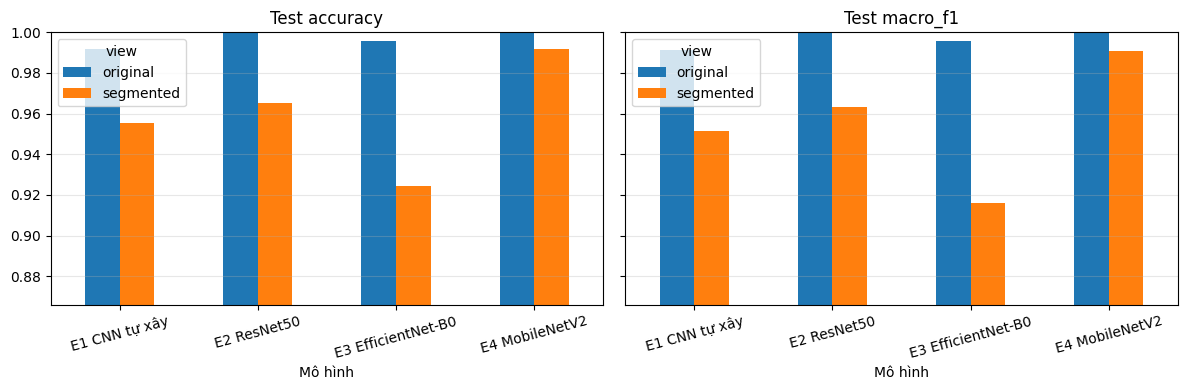

In [ ]:
# 7. Bảng so sánh (đọc lại mọi metrics.json trên Drive)
from IPython.display import display, Markdown, Image as IPImage
CODES = {'custom_cnn': 'E1 CNN tự xây', 'resnet50': 'E2 ResNet50', 'efficientnet_b0': 'E3 EfficientNet-B0', 'mobilenet_v2': 'E4 MobileNetV2'}
rows = [json.loads(p.read_text()) for p in sorted((RESULTS / 'runs').glob('*/metrics.json'))]
df = pd.DataFrame(rows)
df['Mô hình'] = df.model.map(CODES)
cols = ['accuracy', 'balanced_accuracy', 'macro_f1', 'auc_ovr', 'malignant_sensitivity', 'specificity_benign',
        'missed_malignant'] + [f'recall_{c}' for c in CLASSES] + ['best_epoch', 'params_M']
summary = df.groupby(['Mô hình', 'view'])[cols].agg(['mean', 'std'] if df.seed.nunique() > 1 else ['mean'])
summary.columns = [a if b == 'mean' else f'{a}_std' for a, b in summary.columns]
summary.to_csv(RESULTS / 'comparison.csv')
pct = [c for c in summary.columns if not c.startswith(('missed', 'best_epoch', 'params'))]
display(summary.style.format({c: '{:.1%}' for c in pct} | {'params_M': '{:.2f}', 'best_epoch': '{:.0f}', 'missed_malignant': '{:.0f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ['accuracy', 'macro_f1']):
    piv = df.groupby(['Mô hình', 'view'])[metric].mean().unstack()
    piv.plot.bar(ax=ax, rot=15); ax.set_title(f'Test {metric}'); ax.set_ylim(max(0, piv.min().min() - 0.05), 1.0)
    ax.grid(axis='y', alpha=.3)
fig.tight_layout(); fig.savefig(RESULTS / 'fig_accuracy_f1.png', dpi=150); plt.show()

In [ ]:
# 8. So sánh từng cặp mô hình trên cùng view bằng McNemar (seed 42), hiệu chỉnh Holm
from itertools import combinations
from scipy.stats import binomtest
res = []
for view in VIEWS_TO_RUN:
    preds = {}
    for n in MODELS_TO_RUN:
        f = RESULTS / 'runs' / f'{n}_{view}_s42' / 'test_predictions.npz'
        if f.exists():
            d = np.load(f); preds[n] = (d['prob'].argmax(1) == d['y'])
    for a, b in combinations(preds, 2):
        only_a, only_b = int((preds[a] & ~preds[b]).sum()), int((~preds[a] & preds[b]).sum())
        p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        res.append(dict(view=view, A=CODES[a], B=CODES[b], acc_A=preds[a].mean(), acc_B=preds[b].mean(),
                        chỉ_A_đúng=only_a, chỉ_B_đúng=only_b, p=p))
mc = pd.DataFrame(res).sort_values('p').reset_index(drop=True)
m = len(mc); mc['p_holm'] = np.minimum(1, np.maximum.accumulate([(m - i) * p for i, p in enumerate(mc.p)]))
mc['kết luận'] = np.where(mc.p_holm < 0.05, 'khác biệt có ý nghĩa', 'không khác biệt có ý nghĩa')
mc.to_csv(RESULTS / 'mcnemar.csv', index=False)
display(mc.style.format({'acc_A': '{:.1%}', 'acc_B': '{:.1%}', 'p': '{:.3f}', 'p_holm': '{:.3f}'}))

,view,A,B,acc_A,acc_B,chỉ_A_đúng,chỉ_B_đúng,p,p_holm,kết luận
0,segmented,E3 EfficientNet-B0,E4 MobileNetV2,92.5%,99.2%,1,34,0.000,0.000,khác biệt có ý nghĩa
1,segmented,E1 CNN tự xây,E4 MobileNetV2,95.5%,99.2%,1,19,0.000,0.000,khác biệt có ý nghĩa
2,segmented,E2 ResNet50,E4 MobileNetV2,96.5%,99.2%,3,16,0.004,0.044,khác biệt có ý nghĩa
3,segmented,E2 ResNet50,E3 EfficientNet-B0,96.5%,92.5%,33,13,0.005,0.044,khác biệt có ý nghĩa
4,segmented,E1 CNN tự xây,E3 EfficientNet-B0,95.5%,92.5%,29,14,0.032,0.252,không khác biệt có ý nghĩa
5,original,E1 CNN tự xây,E2 ResNet50,99.2%,100.0%,0,4,0.125,0.875,không khác biệt có ý nghĩa
6,original,E1 CNN tự xây,E4 MobileNetV2,99.2%,100.0%,0,4,0.125,0.875,không khác biệt có ý nghĩa
7,segmented,E1 CNN tự xây,E2 ResNet50,95.5%,96.5%,14,19,0.487,1.000,không khác biệt có ý nghĩa
8,original,E2 ResNet50,E3 EfficientNet-B0,100.0%,99.6%,2,0,0.500,1.000,không khác biệt có ý nghĩa
9,original,E3 EfficientNet-B0,E4 MobileNetV2,99.6%,100.0%,0,2,0.500,1.000,không khác biệt có ý nghĩa


custom_cnn_original_s42


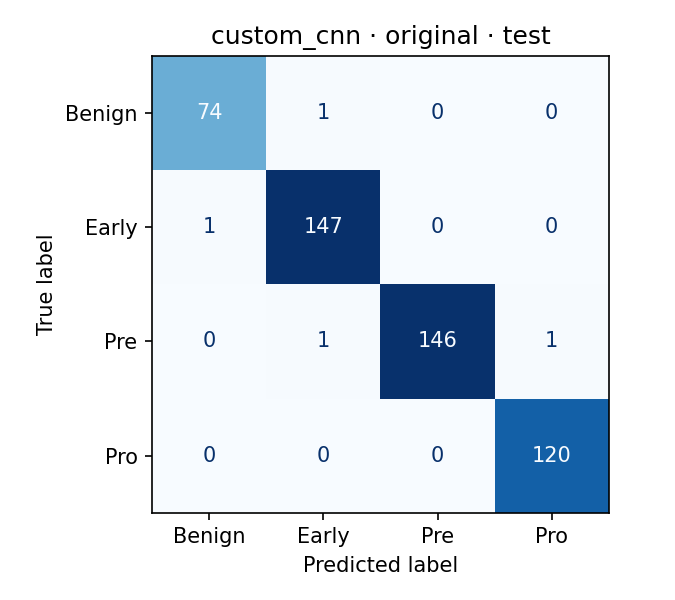

custom_cnn_segmented_s42


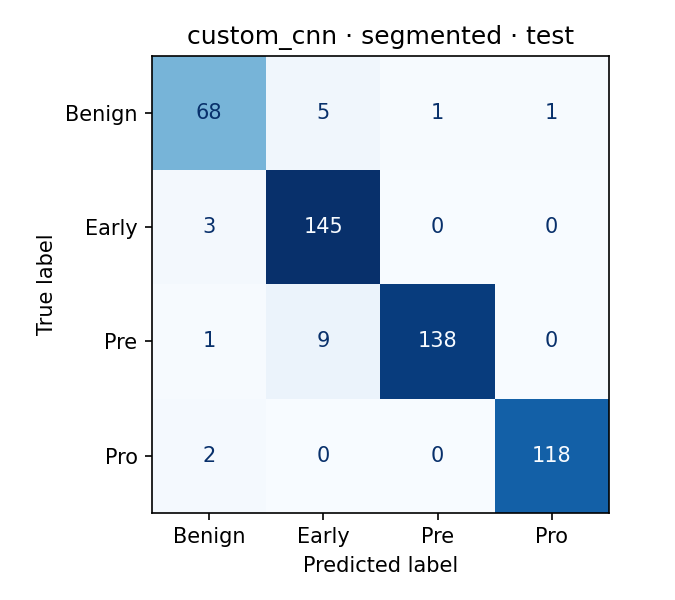

efficientnet_b0_original_s42


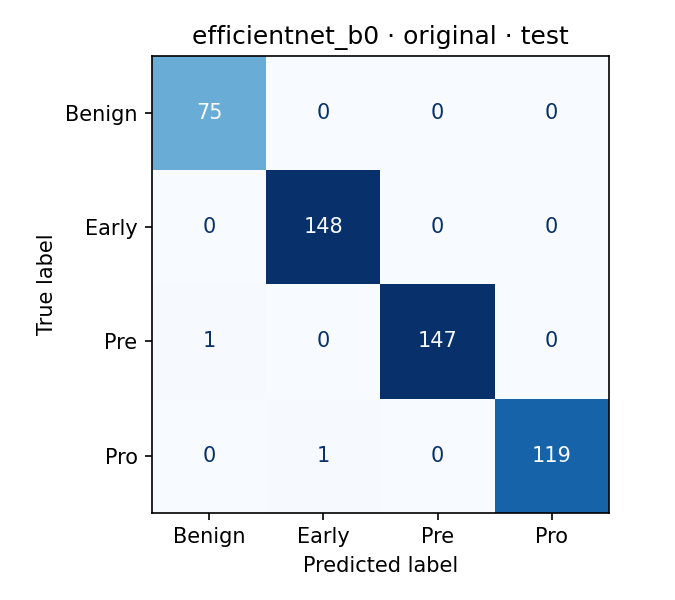

efficientnet_b0_segmented_s42


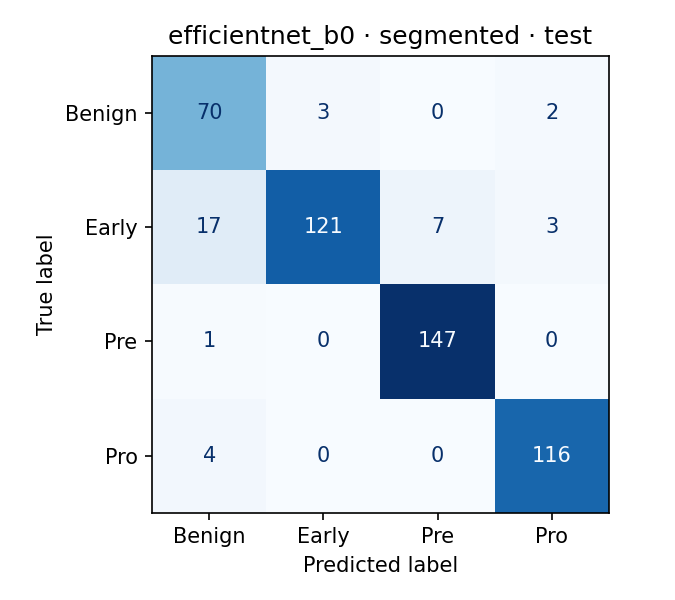

mobilenet_v2_original_s42


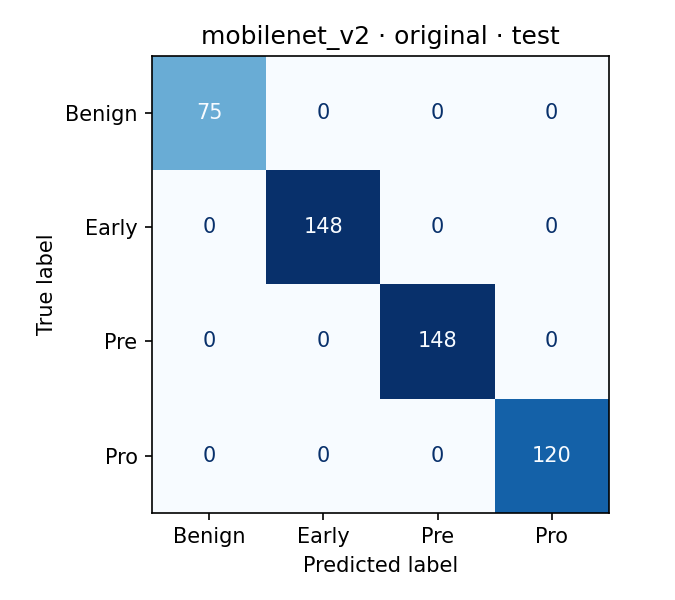

mobilenet_v2_segmented_s42


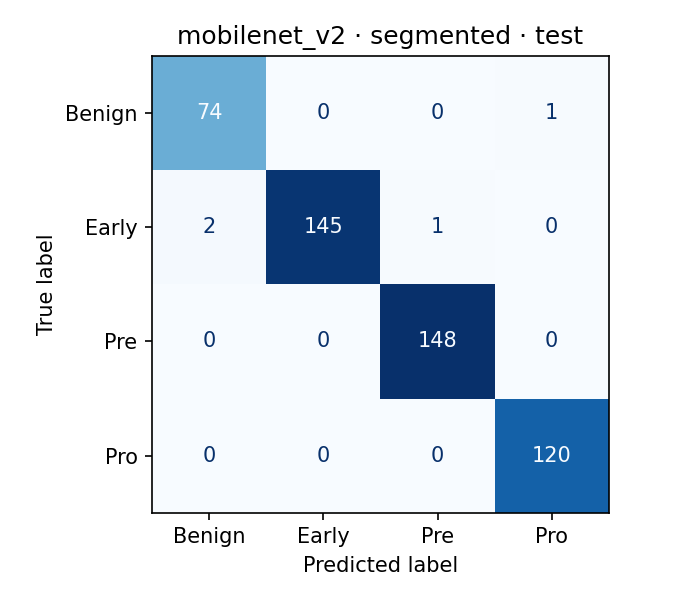

resnet50_original_s42


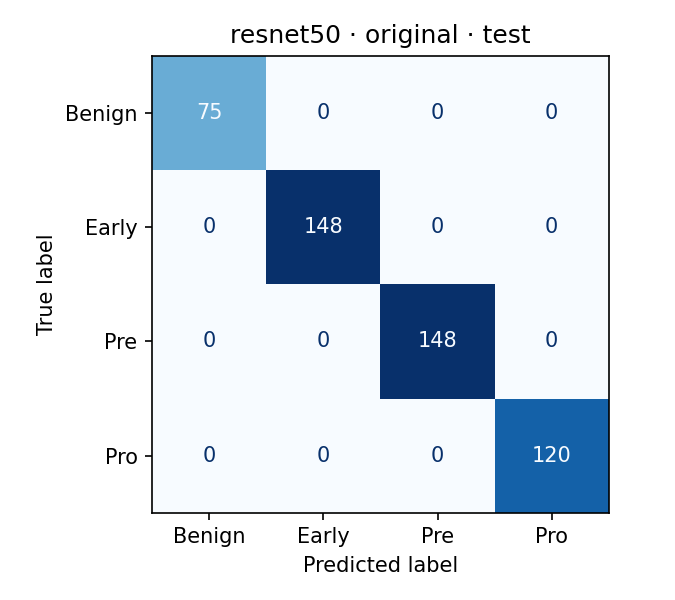

resnet50_segmented_s42


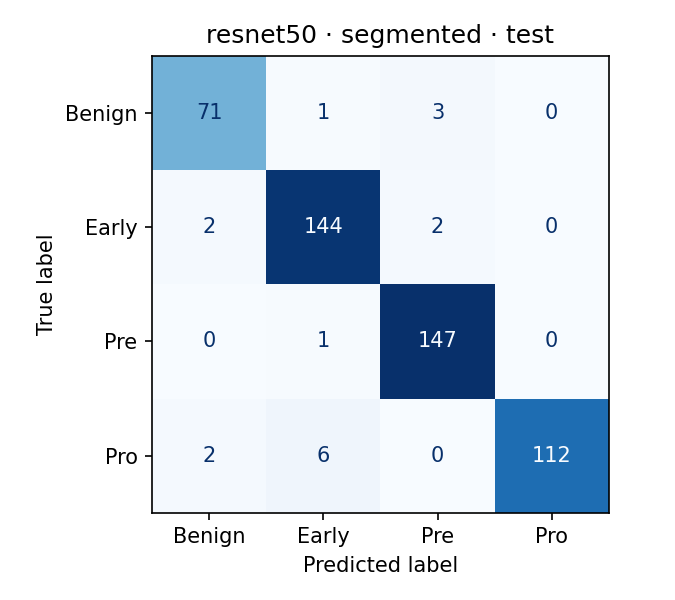

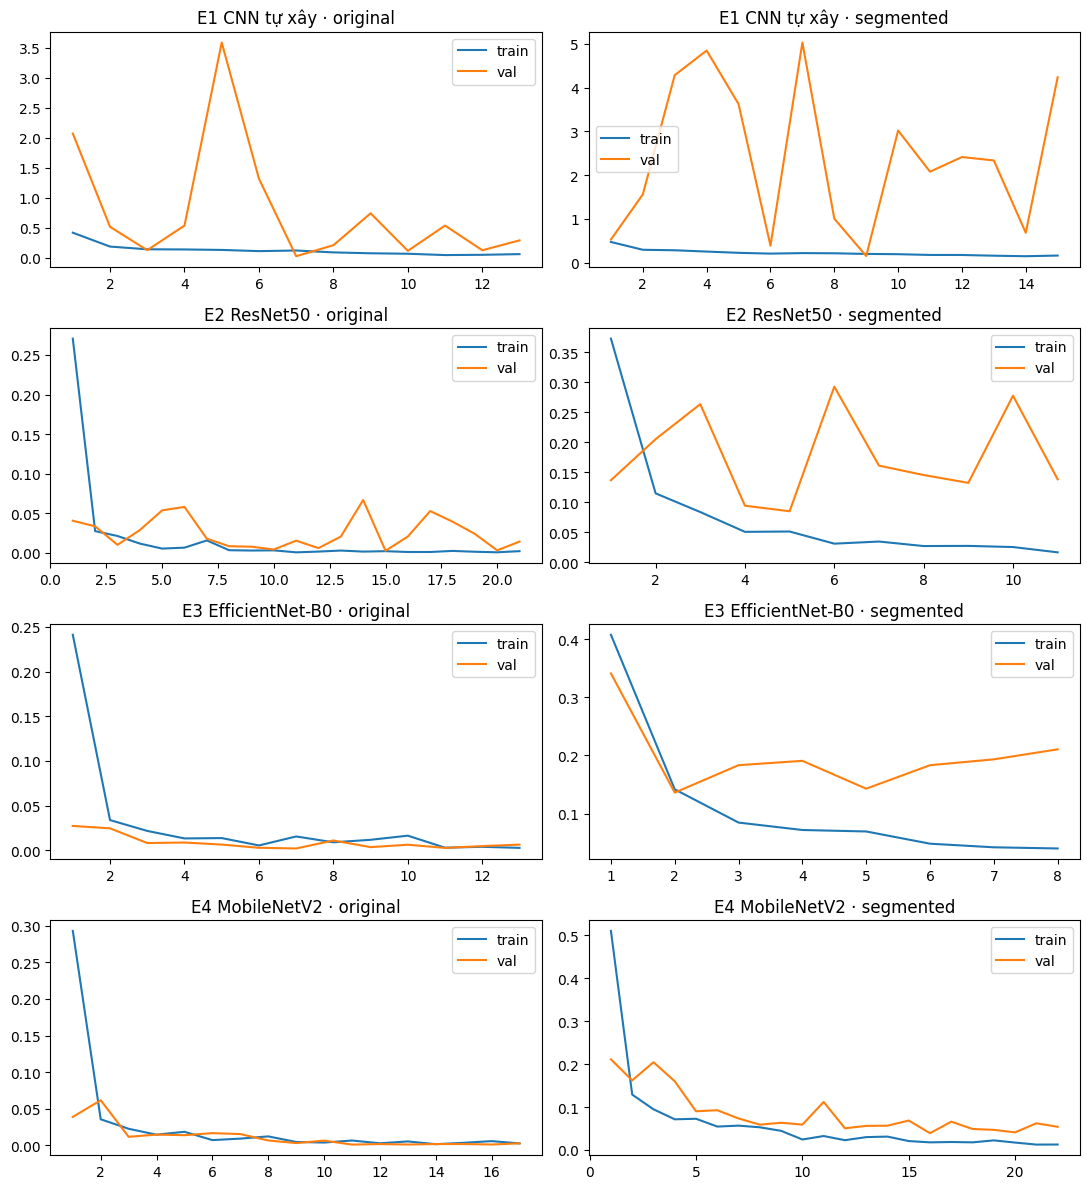

In [ ]:
# 9. Ma trận nhầm lẫn và đường học
for p in sorted((RESULTS / 'runs').glob('*/confusion_test.png')):
    print(p.parent.name); display(IPImage(str(p), width=340))
fig, axes = plt.subplots(len(MODELS_TO_RUN), len(VIEWS_TO_RUN), figsize=(11, 3 * len(MODELS_TO_RUN)), squeeze=False)
for i, n in enumerate(MODELS_TO_RUN):
    for j, v in enumerate(VIEWS_TO_RUN):
        f = RESULTS / 'runs' / f'{n}_{v}_s42' / 'history.csv'
        if f.exists():
            h = pd.read_csv(f); ax = axes[i, j]
            ax.plot(h.epoch, h.train_loss, label='train'); ax.plot(h.epoch, h.val_loss, label='val')
            ax.set_title(f'{CODES[n]} · {v}'); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / 'fig_learning_curves.png', dpi=130); plt.show()

**Lưu ý khi đọc kết quả:** split gom nhóm theo ảnh trùng/gần trùng nhưng không có thông tin bệnh nhân/tiêu bản, nên kết quả test có thể lạc quan hơn khi áp dụng thực tế.
Đây là mô hình nghiên cứu sàng lọc, không thay thế đánh giá của bác sĩ huyết học.